In [2]:
from sklearn.datasets import make_classification
import pennylane as qml
from pennylane import numpy as np


# Dummy binary data
X, _ = make_classification(
    n_samples=100,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    random_state=0,
)
X_bin = (X > 0).astype(int)

(<Figure size 1000x500 with 1 Axes>, <Axes: >)

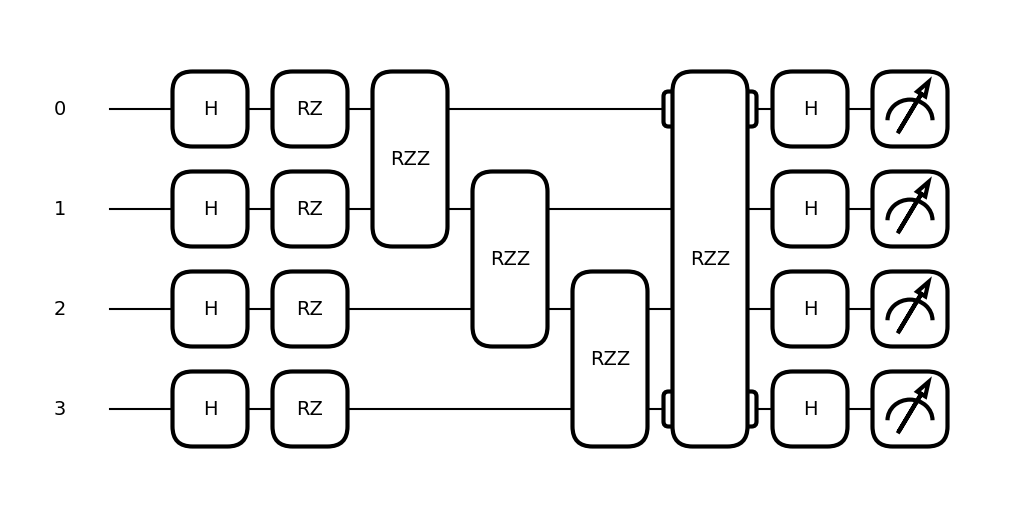

In [14]:
# Tiny Born machine (already 'trained' with random params for demo)
n_qubits = 4
dev = qml.device("lightning.qubit", wires=n_qubits+1, shots=None)

@qml.qnode(dev)
def circuit(params):
    qml.broadcast(qml.Hadamard, pattern="single", wires=range(n_qubits))
    qml.broadcast(qml.RZ, parameters=params[0] , wires=range(n_qubits), pattern="single")
    for j in range(n_qubits):
        qml.PauliRot(params[1][j], "ZZ", wires=[j, (j + 1) % n_qubits])
    qml.broadcast(qml.Hadamard, pattern="single", wires=range(n_qubits))
    return qml.probs(wires=range(n_qubits))

params = np.random.uniform(-np.pi, np.pi, (2,n_qubits), requires_grad=True)

qml.draw_mpl(circuit)(params)

In [ ]:
from qasp.qkernels import QFKernel

In [16]:
qfk = QFKernel(circuit, params, fisher="quantum")
qfk_gram = qfk.gram(X_bin, X_bin)
print("\nNormalised Gram matrix for 5 samples:\n", 
        qfk_gram)


Normalised Gram matrix for 5 samples:
 [[ 47.6587519   33.14897959   5.42649406 ...  30.4407923   -1.85422955
    3.3850739 ]
 [ 33.14897959 108.837211    -6.92922054 ...  87.201766    -1.30815099
   11.0630488 ]
 [  5.42649406  -6.92922054   8.86002258 ...   3.56089971  -1.56465773
    6.88300737]
 ...
 [ 30.4407923   87.201766     3.56089971 ... 100.74946399  -1.93310502
   13.16160687]
 [ -1.85422955  -1.30815099  -1.56465773 ...  -1.93310502   0.73426658
   -1.37373734]
 [  3.3850739   11.0630488    6.88300737 ...  13.16160687  -1.37373734
   17.24051951]]


In [17]:
cfk = QFKernel(circuit, params, fisher="classical")
cfk_gram = cfk.gram(X_bin, X_bin)
print("\nNormalised Gram matrix for 5 samples:\n", 
        cfk_gram)


Normalised Gram matrix for 5 samples:
 [[ 148.94432121   25.62318769   15.45281426 ... -138.57688129
    -1.03637826   16.99581124]
 [  25.62318769  130.98471623   -7.42843797 ...  123.06683249
    -1.55913713   12.48611692]
 [  15.45281426   -7.42843797   10.62787414 ...  -16.35933665
    -1.4819024     8.87277128]
 ...
 [-138.57688129  123.06683249  -16.35933665 ...  450.97746105
    -3.73785194   -8.67812463]
 [  -1.03637826   -1.55913713   -1.4819024  ...   -3.73785194
     0.75955731   -1.27014271]
 [  16.99581124   12.48611692    8.87277128 ...   -8.67812463
    -1.27014271   20.16569119]]


In [18]:
tol = 1e-10
evals = np.linalg.eigvalsh(qfk_gram)       # after symmetrizing
min_ev = np.min(evals)
is_psd = min_ev >= -tol                 # allow tiny negatives
print(f"smallest eigenvalue: {min_ev:.3e}")
print("PSD? →", is_psd)

# check trace of qfk_gram and cfk_gram
print("Trace of qfk_gram:", np.trace(qfk_gram))
print("Trace of cfk_gram:", np.trace(cfk_gram))

smallest eigenvalue: -6.715e-13
PSD? → True
Trace of qfk_gram: 3791.267551515447
Trace of cfk_gram: 6763.488381742128
